#### 1. Business Understanding
Public transportation services such as Indian Railways receive a large volume of passenger feedback and complaints every day. These complaints cover various issues, including train delays, cleanliness, staff behaviour, ticketing problems, and passenger safety.

Manually reviewing and categorizing thousands of complaints requires significant time and effort. This project uses Natural Language Processing (NLP) and Machine Learning techniques to automatically analyze passenger feedback and classify complaints into predefined categories.
#### 2. Business Problem
Transportation authorities receive passenger complaints in unstructured text formats through social media and other feedback channels. Due to the large volume of messages, identifying the actual issue and directing it to the appropriate department can be challenging.

An automated complaint classification system can help organize passenger feedback, reduce manual categorization efforts, and support more efficient complaint management.
#### 3. Business Objectives
The main business objectives of this project are:
1. Automate Complaint Classification: Automatically categorize passenger complaints based on their textual content.
2. Improve Complaint Management: Reduce the manual effort required to review and organize passenger feedback.
3. Identify Common Issues: Understand frequently reported problems across transportation services.
4. Support Decision-Making: Provide categorized feedback that can help transportation authorities identify areas requiring improvement.
5. Enhance Passenger Experience: Support more organized complaint handling and service improvement.
#### 4. Project Objectives
The technical objectives of this project are:
1. Load and explore the Indian Railways complaint tweets dataset.
2. Perform data cleaning and exploratory data analysis.
3. Apply NLP preprocessing techniques to clean passenger feedback.
4. Convert textual complaints into numerical features using TF-IDF.
5. Implement and compare multiple machine learning classification algorithms.
6. Evaluate model performance using accuracy, precision, recall, F1-score, and confusion matrix.
7. Select the best-performing classification model.
8. Develop an interactive complaint prediction application using Gradio.
#### 5. Problem Statement
To develop an NLP-based Machine Learning classification system that analyzes passenger feedback and automatically categorizes transportation-related complaints into five major categories:
- Delays
- Cleanliness
- Staff Behaviour
- Ticketing
- Safety
The system aims to simplify complaint categorization and provide structured insights into passenger concerns using text preprocessing, TF-IDF feature extraction, and supervised machine learning algorithms.
#### 6. Proposed Solution
The proposed solution involves developing a text classification model using the Indian Railways complaint tweets dataset. The system will preprocess passenger feedback, extract meaningful textual features using TF-IDF, and train multiple machine learning algorithms to predict complaint categories.

The best-performing model will be integrated into a Gradio application, allowing users to enter passenger complaints and receive automatically predicted categories.
#### 7. Project Scope
Included in this project:
- Indian Railways passenger feedback analysis.
- Five-category complaint classification.
- NLP text preprocessing.
- TF-IDF feature extraction.
- Machine learning model comparison.
- Interactive complaint prediction interface.
Out of scope:
- Automatic complaint resolution.
- Direct integration with railway management systems.
- Real-time complaint routing to railway departments.
- Verified classification of bus and metro complaints.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\shara\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
!pip install datasets

In [4]:
%pip uninstall -y pyarrow datasets

Found existing installation: pyarrow 26.0.1
Uninstalling pyarrow-26.0.1:
  Successfully uninstalled pyarrow-26.0.1
Found existing installation: datasets 5.1.0
Uninstalling datasets-5.1.0:
  Successfully uninstalled datasets-5.1.0
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.


In [5]:
%pip install --no-cache-dir pyarrow datasets

   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   - -------------------------------------- 1.3/29.0 MB 10.4 MB/s eta 0:00:03
   --- ------------------------------------ 2.9/29.0 MB 8.6 MB/s eta 0:00:04
   ------- -------------------------------- 5.5/29.0 MB 9.8 MB/s eta 0:00:03
   ---------- ----------------------------- 7.3/29.0 MB 9.7 MB/s eta 0:00:03
   ------------- -------------------------- 9.4/29.0 MB 10.1 MB/s eta 0:00:02
   ---------------- ----------------------- 11.8/29.0 MB 9.9 MB/s eta 0:00:02
   -------------------- ------------------- 14.9/29.0 MB 10.7 MB/s eta 0:00:02
   ----------------------- ---------------- 17.3/29.0 MB 10.9 MB/s eta 0:00:02
   --------------------------- ------------ 19.7/29.0 MB 10.8 MB/s eta 0:00:01
   ----------------------------- ---------- 21.2/29.0 MB 10.5 MB/s eta 0:00:01
   -------------------------------- ------- 23.6/29.0 MB 10.5 MB/s eta 0:00:01
   ----------------------------------- ---- 26.0/29.0 MB 10.6 MB/s eta

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlflow 3.3.2 requires pyarrow<22,>=4.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [6]:
import pyarrow as pa
import datasets

print("PyArrow version:", pa.__version__)
print("Datasets version:", datasets.__version__)

PyArrow version: 26.0.1
Datasets version: 5.1.0


In [7]:
from datasets import load_dataset

ds = load_dataset(
    "faizmubeen/indian_railways_complaint_tweets"
)

print(ds)

DatasetDict({
    train: Dataset({
        features: ['Tweet', 'Label', 'Type'],
        num_rows: 4535
    })
})


In [8]:
df = ds["train"].to_pandas()

display(df.head())

,Tweet,Label,Type
0,Balurghat is suffering from unnecessary late o...,complaint,punctuality
1,My parents travelled by #garibrath train from ...,complaint,cleanliness
2,#IndianRailways no response from IRCTC,complaint,facility
3,Stopped travelling in #IndianRailways way back...,complaint,cleanliness
4,#IndianRailways 02563 BJU NDLS Running late by...,complaint,punctuality


In [9]:
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset Shape: (4535, 3)
Columns: ['Tweet', 'Label', 'Type']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4535 entries, 0 to 4534
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Tweet   4535 non-null   object
 1   Label   4535 non-null   object
 2   Type    4535 non-null   object
dtypes: object(3)
memory usage: 106.4+ KB


In [11]:
print(df.isnull().sum())

Tweet    0
Label    0
Type     0
dtype: int64


In [12]:
# Checking the category distribution
print(df["Type"].value_counts())

Type
punctuality                      900
others                           414
cleanliness                      276
miscellaneous                    240
service                          198
                                ... 
ticket                             1
fun                                1
scenic photo of train journey      1
parcel booking inquiry             1
appreciation for rail route        1
Name: count, Length: 317, dtype: int64


In [13]:
# Check original Label distribution

print(df["Label"].value_counts())

Label
complaint        2615
non_complaint    1920
Name: count, dtype: int64


In [14]:
# Check the top 50 complaint types

print(df["Type"].value_counts().head(50))

Type
punctuality                   900
others                        414
cleanliness                   276
miscellaneous                 240
service                       198
facility                      196
security                      196
informational                 188
electrical equipment          170
staff behaviour               138
corruption / bribery          128
information                   115
appreciation                  111
bed roll                      111
crowding                       85
ticket booking                 77
catering & vending service     72
maintenance                    67
water availability             59
political                      55
refund                         55
safety                         34
news                           28
medical assistance             27
suggestion                     23
food                           22
positive feedback              15
loss/found                     15
general                        14
general i

In [15]:
# Display all unique Type values

print("Total unique types:", df["Type"].nunique())

print(sorted(df["Type"].dropna().unique()))

Total unique types: 317
['achievement', 'advertisement', 'advertisement for exhibition', 'advice/tip', 'age relaxation', 'announcement', 'announcement of new train', 'announcement/update', 'appointment/announcement', 'appreciation', 'appreciation for event', 'appreciation for food quality', 'appreciation for indian railways achievement tweet', 'appreciation for indian railways digitalization efforts', 'appreciation for rail route', 'appreciation for response', 'appreciation for rpf action', 'appreciation of vistadome jan shatabdi express', 'appreciation/experience sharing', 'appreciation/opinion', 'appreciation/positive', 'assistance', 'assistance/help', 'availability', 'awareness', 'awareness/informational', 'bed', 'bed roll', 'booking/refund', 'business news', 'business news about titagarh wagons order from indian railways', 'business revenue generation', 'cancelled train', 'cargo transport', 'catering & vending service', 'celebration', 'celebrations', 'change in preferred transport 

### Visualize original complaint categories

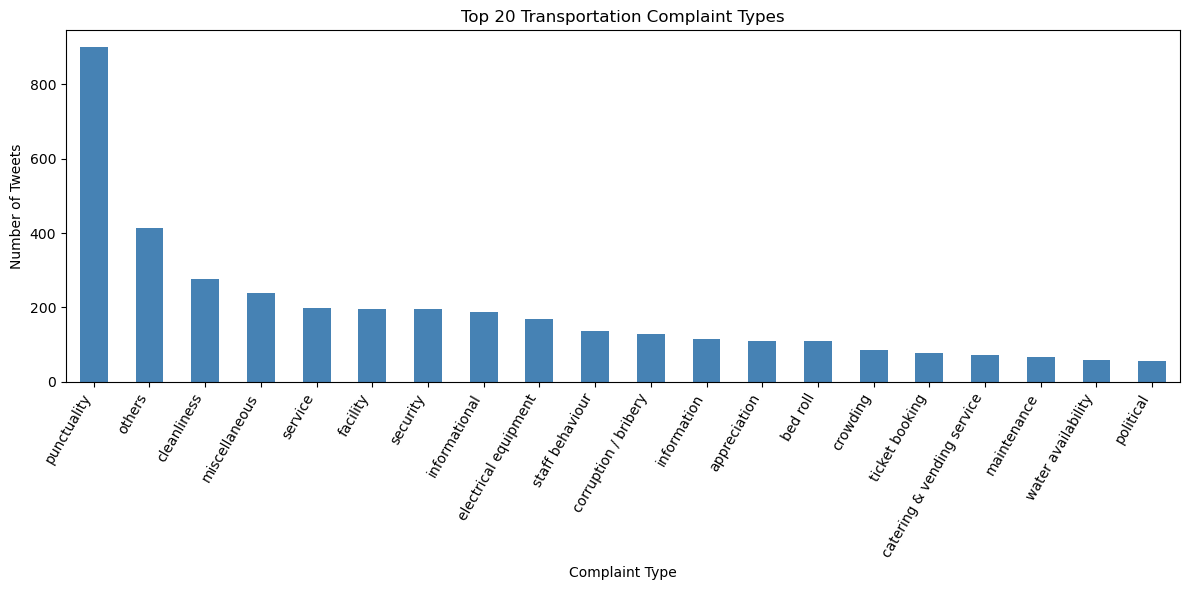

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

df["Type"].value_counts().head(20).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 20 Transportation Complaint Types")
plt.xlabel("Complaint Type")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

### Convert 317 original types into five categories - created a new column called category using the original Type column.

In [17]:
import re

def map_category(value):

    value = str(value).lower().strip()

    # Delays
    if re.search(
        r"punctual|delay|late.?running|train.?running|"
        r"reschedul|time.?table|departure.?time|arrival.?time",
        value
    ):
        return "Delays"

    # Cleanliness
    elif re.search(
        r"clean|hygiene|sanitation|dirty|garbage|"
        r"toilet|washroom|waste",
        value
    ):
        return "Cleanliness"

    # Staff Behaviour
    elif re.search(
        r"staff.?behav|staff.?misbehav|"
        r"rude|misbehav|conductor|"
        r"employee.?behav|porter.?behav",
        value
    ):
        return "Staff Behaviour"

    # Ticketing
    elif re.search(
        r"ticket|reservation|booking|refund|"
        r"fare|payment|pnr|irctc|"
        r"cancellation|catering.?charge",
        value
    ):
        return "Ticketing"

    # Safety
    elif re.search(
        r"safety|security|harass|theft|"
        r"robbery|accident|unsafe|"
        r"emergency|crime",
        value
    ):
        return "Safety"

    else:
        return "Other / Unmapped"

In [18]:
# Keep only actual complaints

df = df[
    df["Label"].str.lower().str.strip() == "complaint"
].copy()

df = df.reset_index(drop=True)

print("Complaint Dataset Shape:", df.shape)

print("\nLabel Distribution:")

print(df["Label"].value_counts())

Complaint Dataset Shape: (2615, 3)

Label Distribution:
Label
complaint    2615
Name: count, dtype: int64


In [19]:
df["category"] = df["Type"].apply(map_category)

print(df["category"].value_counts())

category
Other / Unmapped    1239
Delays               786
Cleanliness          227
Safety               143
Ticketing            134
Staff Behaviour       86
Name: count, dtype: int64


In [20]:
print(df["category"].value_counts())

category
Other / Unmapped    1239
Delays               786
Cleanliness          227
Safety               143
Ticketing            134
Staff Behaviour       86
Name: count, dtype: int64


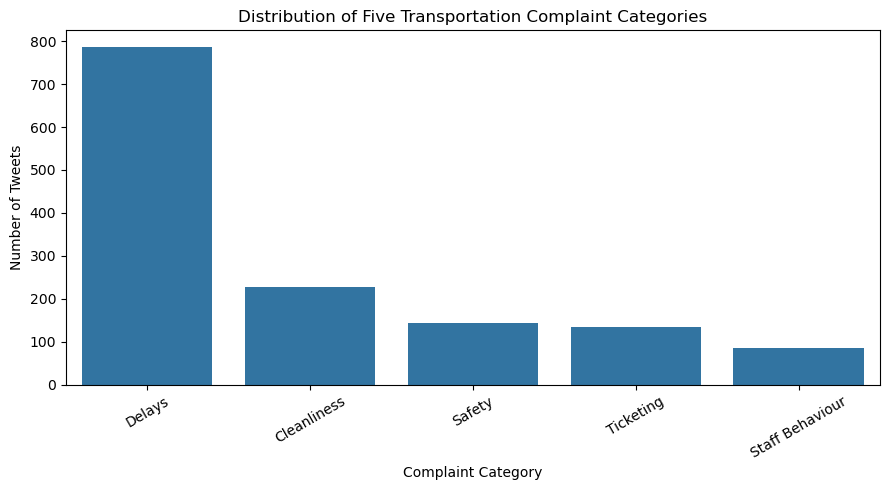

In [21]:
# visualize the five categories
category_counts = df[
    df["category"] != "Other / Unmapped"
]["category"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Distribution of Five Transportation Complaint Categories")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
# Inspect unmapped categories

unmapped = df[
    df["category"] == "Other / Unmapped"
]

print("Unmapped records:", len(unmapped))

print("\nUnmapped Type values:")

print(
    unmapped["Type"].value_counts().head(100)
)

Unmapped records: 1239

Unmapped Type values:
Type
service                                                       180
miscellaneous                                                 177
facility                                                      142
bed roll                                                      102
corruption / bribery                                          101
electrical equipment                                           95
crowding                                                       85
catering & vending service                                     71
others                                                         68
maintenance                                                    64
political                                                      52
water availability                                             45
food                                                           16
loss/found                                                     14
medical assistance       

In [23]:
df_final = df[
    df["category"] != "Other / Unmapped"
].copy()

df_final = df_final[
    ["Tweet", "category"]
]

df_final.columns = [
    "complaint",
    "category"
]

df_final = df_final.reset_index(drop=True)

print("Final Dataset Shape:", df_final.shape)

print("\nFinal Category Distribution:")

print(df_final["category"].value_counts())

Final Dataset Shape: (1376, 2)

Final Category Distribution:
category
Delays             786
Cleanliness        227
Safety             143
Ticketing          134
Staff Behaviour     86
Name: count, dtype: int64


In [24]:
print(df_final["category"].value_counts())

print("\nTotal records:", len(df_final))

category
Delays             786
Cleanliness        227
Safety             143
Ticketing          134
Staff Behaviour     86
Name: count, dtype: int64

Total records: 1376


### NLP Text Preprocessing

In [25]:
import re
import string

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

# Preserve negation words

important_words = {
    "not", "no", "nor", "never"
}

def clean_text(text):

    # Convert to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    words = text.split()

    # Remove stopwords but preserve negations
    words = [
        word for word in words
        if word not in stop_words or word in important_words
    ]

    return " ".join(words)

In [26]:
# Apply Preprocessing

df_final["cleaned_complaint"] = (
    df_final["complaint"].apply(clean_text)
)

display(
    df_final[
        ["complaint", "cleaned_complaint", "category"]
    ].head(10)
)

,complaint,cleaned_complaint,category
0,Balurghat is suffering from unnecessary late o...,balurghat suffering unnecessary late following...,Delays
1,My parents travelled by #garibrath train from ...,parents travelled garibrath train raipur luckn...,Cleanliness
2,Stopped travelling in #IndianRailways way back...,stopped travelling indianrailways way back sti...,Cleanliness
3,#IndianRailways 02563 BJU NDLS Running late by...,indianrailways bju ndls running late hrs bad s...,Delays
4,#UTS app wants me to be away at certain distan...,uts app wants away certain distance railway st...,Ticketing
5,"Sir, this is the condition of ticket booking c...",sir condition ticket booking counter guwahati ...,Ticketing
6,Thinking of whether it is passenger train or e...,thinking whether passenger train express lalba...,Delays
7,I boarded the train 09268 from pune yesterday....,boarded train pune yesterday train already hou...,Delays
8,#IndianRailways \nFrom 10th June till date no ...,indianrailways th june till date no tickets ms...,Ticketing
9,What's the reason to stop the train no 09420 a...,reason stop train no maninagar hour every pass...,Delays


In [27]:
# Compare original and cleaned text

for i in range(5):

    print("Original:", df_final["complaint"].iloc[i])

    print("Cleaned:", df_final["cleaned_complaint"].iloc[i])

    print("-" * 60)

Original: Balurghat is suffering from unnecessary late of the following  train (13161) continuously. #IndianRailways is incessantly ignoring the sufferings. How does a train take 7 hours for 350 kms &amp; almost  5 hours for rest 100 kms despite auto signal and crossing? Shame #ashwinivaishnaw https://t.co/kG03fPuO3y
Cleaned: balurghat suffering unnecessary late following train continuously indianrailways incessantly ignoring sufferings train take hours kms amp almost hours rest kms despite auto signal crossing shame ashwinivaishnaw
------------------------------------------------------------
Original: My parents travelled by #garibrath train from Raipur to Lucknow after 3 years and were extremely disgusted by the state of #biotoilets
We have travelled by garib rath so many times earlier but never seen such bad condition 
#IndianRailways
Cleaned: parents travelled garibrath train raipur lucknow years extremely disgusted state biotoilets travelled garib rath many times earlier never see

### Feature Extraction using TF-IDF

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [29]:
from sklearn.model_selection import train_test_split

X = df_final["cleaned_complaint"]
y = df_final["category"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1100
Testing records: 276


In [30]:
# Convert text into TF-IDF features
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)

print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1100, 3748)
Testing TF-IDF shape: (276, 3748)


### Model Training

In [31]:
# Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [32]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [33]:
# Support Vector Machine
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print("SVM model trained successfully!")

SVM model trained successfully!


### Model Evaluation

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_predictions = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "SVM": svm_predictions
}

results = []

for model_name, predictions in models_predictions.items():

    results.append({

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Weighted F1,Macro F1
0,Naive Bayes,0.6449,0.5749,0.6449,0.5492,0.3082
1,Logistic Regression,0.8623,0.8559,0.8623,0.8561,0.7425
2,SVM,0.8442,0.8362,0.8442,0.8342,0.7140


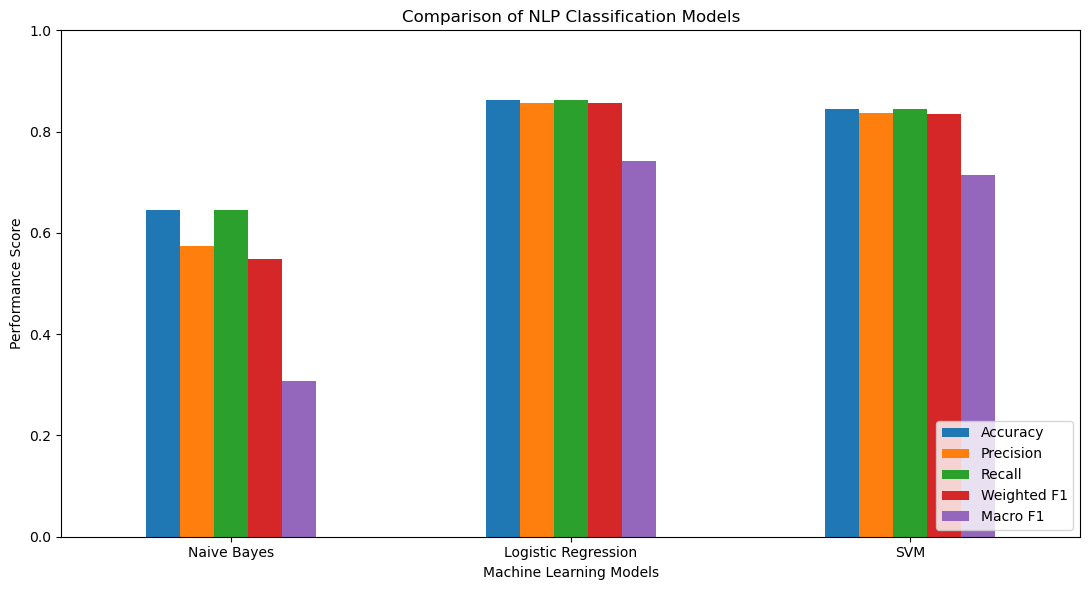

In [35]:
# Visualize model comparision
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of NLP Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

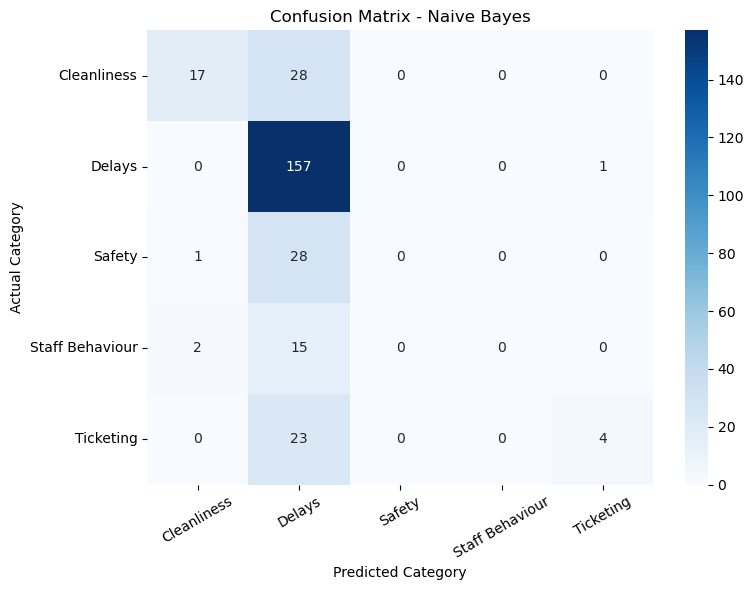

In [36]:
# Confusion matrix - Naive bayes
from sklearn.metrics import confusion_matrix
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Naive Bayes")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=30)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

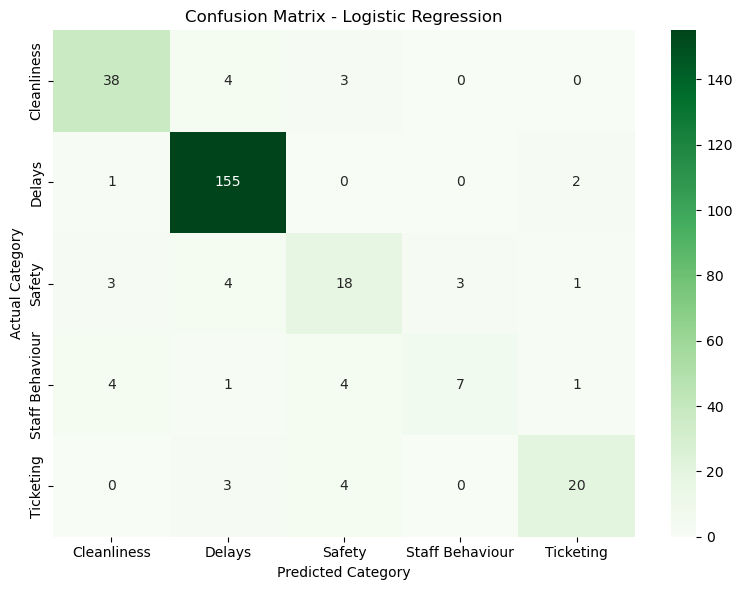

In [37]:
# Logistic Regression - confusion matrix
cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

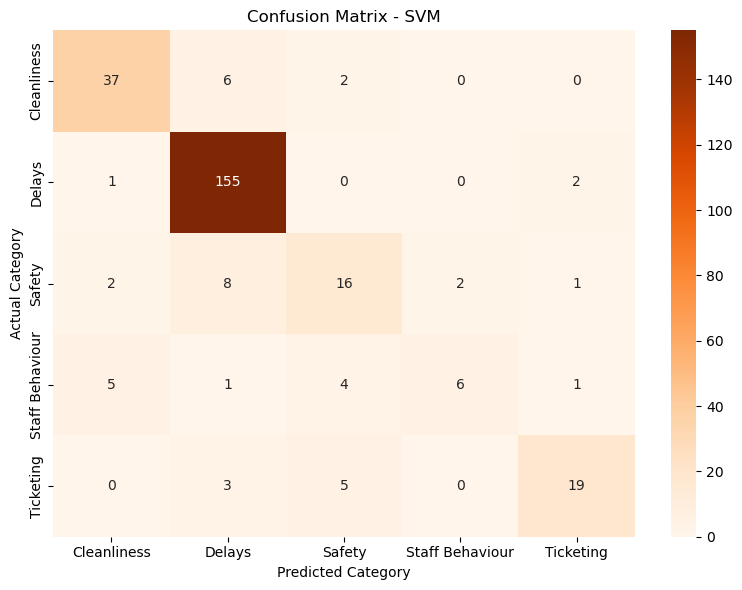

In [38]:
# SVM - Confusion Matrix
cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

In [39]:
best_model_name = results_df.loc[
    results_df["Macro F1"].idxmax(),
    "Model"
]

models = {
    "Naive Bayes": nb_model,
    "Logistic Regression": lr_model,
    "SVM": svm_model
}

best_model = models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best Macro F1:",
    results_df["Macro F1"].max()
)

Best Model: Logistic Regression
Best Macro F1: 0.7425065776384235


In [40]:
# Test new passenger complaints

def predict_complaint(complaint):

    # Clean the complaint
    cleaned = clean_text(complaint)

    # Convert text into TF-IDF features
    text_features = tfidf.transform([cleaned])

    # Predict category
    prediction = best_model.predict(text_features)

    return prediction[0]

In [41]:
sample_complaints = [

    "The train is running two hours late",

    "The railway station toilets are very dirty",

    "The railway staff behaved rudely with passengers",

    "I am unable to book my railway ticket online",

    "There is no proper security at the railway station"

]
for complaint in sample_complaints:

    result = predict_complaint(complaint)
    print("Passenger Complaint:", complaint)
    print("Predicted Category:", result)
    print("-" * 60)

Passenger Complaint: The train is running two hours late
Predicted Category: Delays
------------------------------------------------------------
Passenger Complaint: The railway station toilets are very dirty
Predicted Category: Cleanliness
------------------------------------------------------------
Passenger Complaint: The railway staff behaved rudely with passengers
Predicted Category: Staff Behaviour
------------------------------------------------------------
Passenger Complaint: I am unable to book my railway ticket online
Predicted Category: Ticketing
------------------------------------------------------------
Passenger Complaint: There is no proper security at the railway station
Predicted Category: Safety
------------------------------------------------------------


In [42]:
# Save the trained model

import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "best_model.pkl"
)
joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)
print("Model saved successfully!")


Model saved successfully!


In [43]:
loaded_model = joblib.load(
    "models/best_model.pkl"
)

loaded_tfidf = joblib.load(
    "models/tfidf_vectorizer.pkl"
)

print("Model and vectorizer loaded successfully!")

Model and vectorizer loaded successfully!


In [44]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.


In [45]:
%pip install --upgrade gradio

Note: you may need to restart the kernel to use updated packages.


In [46]:
import gradio as gr

def classify_complaint(text):
    if not text or not text.strip():

        return "Please enter a passenger complaint."

    # Preprocess text
    cleaned = clean_text(text)

    # TF-IDF transformation
    features = loaded_tfidf.transform([cleaned])

    # Prediction
    prediction = loaded_model.predict(features)

    return "Complaint Category: " + prediction[0]

demo = gr.Interface(

    fn=classify_complaint,

    inputs=gr.Textbox(
        lines=4,
        label="Enter Passenger Complaint",
        placeholder="Example: The train is running late..."
    ),

    outputs=gr.Textbox(
        label="Predicted Complaint Category"
    ),

    title="Public Transportation Complaint Classification",

    description=(
        "An NLP-based machine learning application "
        "that classifies Indian Railway passenger feedback "
        "into five complaint categories."
    ),

    examples=[
        ["The train is running two hours late"],
        ["The railway station toilets are very dirty"],
        ["The railway staff behaved rudely"],
        ["I cannot book my railway ticket"],
        ["There is no proper security at the station"]
    ]
)

demo.launch(
    share=False,
    server_name="127.0.0.1",
    server_port=7860
)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
